# **LPG Jet Fire Thermal Radiation Simulation using TNO Model**


This notebook implements a quantitative process safety engineering model to simulate high-pressure LPG release, choked gas discharge, jet flame geometry, and thermal radiation decay curves for Quantitative Risk Assessment (QRA).


### **Model Overview**:
1. Compressible Fluid Dynamics: Calculates choked sonic flow, exit density, equivalent orifice diameter, and jet mass flow rate.
2. TNO Consequence Methodology: Solves non-linear equations for flame frustum geometry, wind-induced tilt angle ($\alpha$), lift-off distance, and Surface Emissive Power (SEP).
3. Thermal Attenuation & Hazard Radii: Computes geometric view factors ($F_{view}$) and atmospheric transmissivity ($\tau$) to evaluate thermal radiation flux ($\text{kW/m}^2$) against safety critical thresholds:
- $4.7 \text{ kW/m}^2$: Threshold for human skin pain and 2nd-degree burns (10-second exposure).
- $12.5 \text{ kW/m}^2$: Structural steel damage and wood ignition threshold.




### **1. Environment Setup & Configuration Handling**

Subtask:
Import required numerical and optimization libraries, and define dynamic parameter loading with fallback safety defaults.

Reasoning:
The simulation requires 18 physical input parameters (e.g., storage pressure, ambient temperature, hole diameter, wind speed). A robust configuration handler reads from lpg.json when available, falling back to industry-standard propane/LPG properties if the file is unreadable.


In [ ]:
from math import sqrt, pi, log, exp, sin, cos, radians, degrees, atan
from scipy.optimize import fsolve
from numpy import arctan
import json
import matplotlib.pyplot as plt
import numpy as np

class JetFire:
    def __init__(self, config_file='lpg.json'):
        # Robust JSON loading with default fallback
        try:
            with open(config_file, 'r', encoding='utf-8-sig') as f:
                self.config = json.load(f)
        except Exception:
            self.config = {
                "STORAGE_PRESSURE": 1e7,
                "AMBIENT_PRESSURE": 1.01325e5,
                "STORAGE_TEMP": 288.15,
                "AMBIENT_TEMP": 288,
                "GAS_CONSTANT": 8.314,
                "SPECIFIC_GAS_CONSTANT": 518.28,
                "MOLECULAR_MASS": 1.604e-2,
                "MOLECULAR_MASS_AIR": 2.896e-2,
                "POISSON_CONSTANT": 1.30788,
                "HOLE_DIAMETER": 0.1,
                "MACH_DISTANCE": 3.5,
                "C_E": 0.2,
                "WIND_SPEED": 5,
                "OUTFLOW_ANGLE": 85,
                "GRAVITY_CONSTANT": 9.80665,
                "HEAT_OF_COMBUSTION": 5e7,
                "DISTANCE_FROM_TARGET": 150,
                "HUMIDITY": 0.7
            }

        self.p_v = self.config['STORAGE_PRESSURE']
        self.p_a = self.config['AMBIENT_PRESSURE']
        self.temp_v = self.config['STORAGE_TEMP']
        self.temp_a = self.config['AMBIENT_TEMP']
        self.gas_constant = self.config['GAS_CONSTANT']
        self.gas_constant_i = self.config['SPECIFIC_GAS_CONSTANT']
        self.molecular_mass = self.config['MOLECULAR_MASS']
        self.w_air = self.config['MOLECULAR_MASS_AIR']
        self.gamma = self.config['POISSON_CONSTANT']
        self.D_e = self.config['HOLE_DIAMETER']
        self.x = self.config['MACH_DISTANCE']
        self.c_e = self.config['C_E']
        self.u_w = self.config['WIND_SPEED']
        self.theta_j = self.config['OUTFLOW_ANGLE']
        self.gravity = self.config['GRAVITY_CONSTANT']
        self.heat_of_combustion = self.config['HEAT_OF_COMBUSTION']
        self.X = self.config['DISTANCE_FROM_TARGET']
        self.tau = 0.71474
        self.humidity = self.config['HUMIDITY']

    def calculate_gas_density(self, molecular_mass, pressure, temperature):
        return (molecular_mass * pressure) / (self.gas_constant * temperature)

    def density_on_exit(self, rho_v):
        return rho_v * (2 / (self.gamma + 1)) ** (self.gamma / (self.gamma - 1))

    def velocity_on_exit(self):
        return sqrt((2 * self.gamma) / (self.gamma + 1) * self.gas_constant_i * self.temp_v)

    def mass_flow(self, rho, velocity):
        return rho * velocity * ((pi * (self.D_e ** 2)) / 4)

    def d_equivalent(self, rho_e, rho_a):
        return self.D_e * sqrt(rho_e / rho_a)

    def velocity_at_x(self, d_eq, v_e):
        return 6 * ((d_eq * v_e) / self.x)

    def modeled_diamater(self, m_e, rho_a, v_x, d_eq):
        denom = 2 * pi * rho_a * v_x * d_eq * self.x * (0.082 ** 2)
        nomin = m_e * self.c_e
        brack = 1 - nomin / denom
        ln = log(brack)
        return 2 * sqrt(2) * 0.082 * self.x * sqrt(-ln)

### **2. TNO Consequence Modeling & Flame Geometry Solver**

Subtask:Define the JetFireTNO subclass to compute sonic release velocity, flame frustum dimensions, surface area, and non-linear tilt angle equations using scipy.optimize.fsolve.

Reasoning: High-pressure gas release results in choked compressible flow at the orifice. The TNO model calculates expanded jet velocity, wind drag bending angle ($\alpha$), base/tip flame widths ($w_1, w_2$), and total surface area ($A$) to establish Surface Emissive Power (SEP).

In [ ]:
class JetFireTNO(JetFire):

    def mass_fraction(self):
        return self.molecular_mass / (15.816 * self.molecular_mass + 0.0395)

    def temperature_of_expanding_jet(self):
        return self.temp_v * ((self.p_a / self.p_v) ** ((self.gamma - 1) / self.gamma))

    def static_pressure(self):
        return self.p_v * ((2 / (self.gamma + 1)) ** (self.gamma / (self.gamma - 1)))

    def mach_number(self, p_c):
        p_ratio = (p_c / self.p_a) ** ((self.gamma - 1) / self.gamma)
        return sqrt(((self.gamma + 1) * p_ratio - 2) / (self.gamma - 1))

    def exit_velocity(self, m_j, t_j, w_g):
        return m_j * sqrt(self.gamma * (self.gas_constant * t_j / self.molecular_mass))

    def wind_ratio(self, u_j):
        return self.u_w / u_j

    def effective_source_d(self, rho_jet, rho_a):
        return self.D_e * sqrt(rho_jet / rho_a)

    def auxilary_coefficients(self, d_s, u_j, w_g):
        self.c_a = 0.024 * ((self.gravity * (d_s / (u_j ** 2))) ** (1 / 3))
        self.c_b = 0.2
        self.c_c = (2.85 / w_g) ** (2 / 3)

    def auxilary_eq(self, y):
        return self.c_a * (y ** (5 / 3)) + self.c_b * (y ** (2 / 3)) - self.c_c

    def flame_length(self, y_a, d_s):
        return y_a * d_s

    def frustrum_length(self, l_b0):
        return l_b0 * (0.51 * exp(-0.4 * self.u_w) + 0.49) * (1.0 - 6.07e-3 * (self.theta_j - 90))

    def richardson_nu(self, l_b0, d_s, u_j):
        return l_b0 * (self.gravity / (d_s ** 2 * u_j ** 2)) ** (1 / 3)

    def alpha_angle(self, r_w, r_i):
        if r_w <= 0.05:
            return (self.theta_j - 90) * (1 - exp(-25.6 * r_w)) + (8000 * r_w) / r_i
        else:
            return (self.theta_j - 90) * (1 - exp(-25.6 * r_w)) + (143 + 1726 * sqrt(r_w - 0.026)) / r_i

    def lift_off_flame(self, l_b, alpha, r_w):
        k = 0.185 * exp(-20 * r_w) + 0.015
        return l_b * (sin(radians(k * alpha)) / sin(radians(alpha)))

    def frustrum_r(self, l_b, b_lf, alpha):
        return sqrt((l_b ** 2) - (b_lf ** 2) * (sin(radians(alpha)) ** 2)) - b_lf * cos(radians(alpha))

    def density_ratio(self, t_j):
        return t_j * self.w_air / (self.temp_a * self.molecular_mass)

    def richardson_frustrum(self, d_s, u_j, r_w):
        ri = (self.gravity / (d_s ** 2 * u_j ** 2)) ** (1 / 3) * d_s
        c_prim = 1000 * exp(-100 * r_w) + 0.8
        return ri, c_prim

    def frustrum_base_width(self, rich_f, c_prim, r_w, d_s, density_ratio):
        e = exp(-70 * (rich_f ** (c_prim * r_w)))
        minus = 1 - ((1 - (sqrt(density_ratio) / 15)) * e)
        part = d_s * (13.5 * exp(-6 * r_w) + 1.5)
        return part * minus

    def frustrum_tip_width(self, l_b, r_w):
        return l_b * (0.18 * exp(-1.5 * r_w) + 0.31) * (1 - 0.47 * exp(-25 * r_w))

    def surface_area(self, w_1, w_2, f_r):
        return (pi / 4) * (w_1 ** 2 + w_2 ** 2) + (pi / 2) * (w_1 + w_2) * sqrt((f_r ** 2) + (((w_2 - w_1) / 2) ** 2))

    def net_heat_per_time(self, mass_rate):
        return mass_rate * self.heat_of_combustion

    def heat_fraction(self, u_j):
        return 0.21 * exp(-0.00323 * u_j) + 0.11

    def sep(self, f_s, q_t, A):
        return f_s * q_t / A

    def distance(self, alpha, b_lf, w_1, w_2):
        theta_prim = 90 - self.theta_j + alpha - degrees(atan(b_lf * sin(radians(self.theta_j)) / (self.X - b_lf * cos(radians(self.theta_j)))))
        x_prim = sqrt((b_lf * sin(radians(self.theta_j))) ** 2 + (self.X - b_lf * cos(radians(self.theta_j))) ** 2)
        x_s = x_prim - (w_1 + w_2) / 4
        return theta_prim, x_prim, x_s

    def view_factor(self, x_prim, theta_prim, f_r, w_1, w_2):
        r = (w_1 + w_2) / 4
        a = f_r / r
        b = x_prim / r
        A = sqrt(a ** 2 + (b + 1) ** 2 - 2 * a * (b + 1) * sin(radians(theta_prim)))
        B = sqrt(a ** 2 + (b - 1) ** 2 - 2 * a * (b - 1) * sin(radians(theta_prim)))
        C = sqrt(1 + (b ** 2 - 1) * cos(radians(theta_prim)))
        D = sqrt((b - 1) / (b + 1))
        E = (a * cos(radians(theta_prim))) / (b - a * sin(radians(theta_prim)))
        F = sqrt(b ** 2 - 1)
        licz = (a ** 2) + ((b + 1) ** 2) - 2 * b * (1 + a * sin(radians(theta_prim)))
        mian = A * B
        AB = (licz / mian) * atan((A * D) / B)
        l1 = a * b - ((F ** 2) * sin(radians(theta_prim)))
        l2 = F ** 2 * sin(radians(theta_prim))
        suma = atan(l1 / (F * C)) + atan(l2 / (F * C))
        e1 = - E * arctan(D)
        e2 = E * AB
        e3 = cos(radians(theta_prim)) / C * suma
        F_v = (e1 + e2 + e3) / pi

        licz1 = (a ** 2) + ((b + 1) ** 2) - (2 * (b + 1 + a * b * sin(radians(theta_prim))))
        mian1 = A * B
        AB1 = licz1 / mian1 * atan((A * D) / B)
        h1 = atan(1 / D)
        h2 = (sin(radians(theta_prim)) / C) * suma
        h3 = -AB1
        F_h = (h1 + h2 + h3) / pi
        return sqrt(F_v ** 2 + F_h ** 2)

    def calculate_tau(self, x_prim):
        p_w = self.humidity * 1705
        return 2.02 * ((p_w * x_prim) ** -0.08)

    def q_per_m2(self, SEP, f_view, tau):
        if tau is None:
            tau = self.tau
        return SEP * f_view * tau

    def plot_radiation_contour(self, alpha, b_lf, w_1, w_2, SEP, max_distance=300):
        distances = np.linspace(20, max_distance, 150)
        flux_kw = []

        original_X = self.X
        for d in distances:
            self.X = d
            try:
                theta_p, x_p, _ = self.distance(alpha, b_lf, w_1, w_2)
                fv = self.view_factor(x_p, theta_p, f_r, w_1, w_2)
                t_val = self.calculate_tau(x_p)
                q_val = self.q_per_m2(SEP, fv, t_val) / 1000.0
                flux_kw.append(q_val)
            except Exception:
                flux_kw.append(np.nan)

        self.X = original_X

        plt.figure(figsize=(9, 5))
        plt.plot(distances, flux_kw, color='crimson', linewidth=2.5, label='Thermal Radiation Flux (kW/m²)')
        plt.axhline(y=4.7, color='orange', linestyle='--', linewidth=1.5, label='4.7 kW/m² (Pain / 2nd-Degree Burns)')
        plt.axhline(y=12.5, color='darkred', linestyle='--', linewidth=1.5, label='12.5 kW/m² (Structural Damage)')

        plt.title('LPG Jet Fire Thermal Radiation vs. Distance (TNO Model)', fontsize=12, fontweight='bold')
        plt.xlabel('Distance from Leak Target (meters)', fontsize=10)
        plt.ylabel('Thermal Flux (kW/m²)', fontsize=10)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(loc='upper right')
        plt.tight_layout()
        plt.show()

### **3. Simulation Execution & Hazard Evaluation**


Subtask:
Instantiate the simulation pipeline, solve choked gas release properties, compute atmospheric radiation flux at a 150m target, and render the safety threshold graph.

Reasoning: Executing the complete numerical pipeline extracts engineering metrics (discharge rate, flame length, SEP) and plots heat radiation attenuation across safe setback zones.

       LPG JET FIRE SIMULATION RESULTS (TNO MODEL)      
Gas Exit Density (rho_v)      : 66.9539 kg/m³
Choked Discharge Rate (m_e)   : 772.5140 kg/s
Jet Exit Velocity (u_j)       : 915.66 m/s
Flame Frustum Length (l_b)    : 141.68 m
Surface Emissive Power (SEP)  : 518706.33 W/m²
Thermal Flux at Target (150m): 11.24 kW/m²


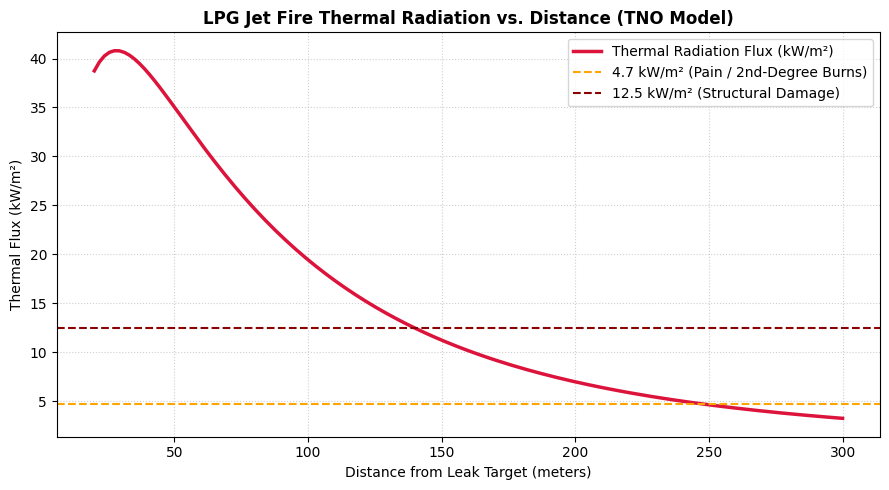

In [ ]:
# Execute Simulation Pipeline
j = JetFireTNO()

rho_v = j.calculate_gas_density(j.molecular_mass, j.p_v, j.temp_v)
rho_a = j.calculate_gas_density(j.w_air, j.p_a, j.temp_a)
t_j = j.temperature_of_expanding_jet()
w_g = j.mass_fraction()
p_c = j.static_pressure()
m_j = j.mach_number(p_c)
u_j = j.exit_velocity(m_j, t_j, w_g)
r_w = j.wind_ratio(u_j)
rho_jet = j.calculate_gas_density(j.molecular_mass, p_c, t_j)
d_s = j.effective_source_d(rho_jet, rho_a)
j.auxilary_coefficients(d_s, u_j, w_g)
y_a = fsolve(j.auxilary_eq, 1)[0]
l_b0 = j.flame_length(y_a, d_s)
l_b = j.frustrum_length(l_b0)
r_i = j.richardson_nu(l_b0, d_s, u_j)
alpha = j.alpha_angle(r_w, r_i)
b_lf = j.lift_off_flame(l_b, alpha, r_w)
f_r = j.frustrum_r(l_b, b_lf, alpha)
density_ratio = j.density_ratio(t_j)
rich_f, c_prim = j.richardson_frustrum(d_s, u_j, r_w)
w_1 = j.frustrum_base_width(rich_f, c_prim, r_w, d_s, density_ratio)
w_2 = j.frustrum_tip_width(l_b, r_w)
A = j.surface_area(w_1, w_2, f_r)
m_e = j.mass_flow(rho_jet, u_j)
q_t = j.net_heat_per_time(m_e)
heat_fraction = j.heat_fraction(u_j)
SEP = j.sep(heat_fraction, q_t, A)
theta_prim, x_prim, x_s = j.distance(alpha, b_lf, w_1, w_2)
f_view = j.view_factor(x_prim, theta_prim, f_r, w_1, w_2)
tau = j.calculate_tau(x_prim)
q_bis = j.q_per_m2(SEP, f_view, tau)

# Print Summary Output Metrics
print("=" * 55)
print("       LPG JET FIRE SIMULATION RESULTS (TNO MODEL)      ")
print("=" * 55)
print(f"Gas Exit Density (rho_v)      : {rho_v:.4f} kg/m³")
print(f"Choked Discharge Rate (m_e)   : {m_e:.4f} kg/s")
print(f"Jet Exit Velocity (u_j)       : {u_j:.2f} m/s")
print(f"Flame Frustum Length (l_b)    : {l_b:.2f} m")
print(f"Surface Emissive Power (SEP)  : {SEP:.2f} W/m²")
print(f"Thermal Flux at Target ({j.X}m): {q_bis / 1000.0:.2f} kW/m²")
print("=" * 55)

# Render Thermal Flux Contour Curve
j.plot_radiation_contour(alpha, b_lf, w_1, w_2, SEP)